# 05 — Fairness audit: does the model work equally well for different students?

Demographics are never model inputs, but that does not make a model fair. If some groups use the VLE differently, for example because of disability, caring responsibilities or digital access, the model can still miss them or misjudge their risk. Digital-only services can exclude people in exactly this way (Wilson-Nash, Angell et al., 2025, *Psychology & Marketing*, "No App, No Entry").

The audit joins demographic groups back to **held-out** stage 3 predictions (weeks 2–12, 10% weekly contact capacity) and asks, for each group:

| Measure | Question |
| --- | --- |
| **Miss rate** | Of the group's upcoming disengagements, what share is *not* flagged? |
| **Calibration ratio** | Mean predicted risk ÷ observed rate. 1 means the probability a tutor sees is accurate for that group. |
| **Flag rate, precision, AUC** | How often is the group flagged, how often correctly, and how well are students within it ranked? |
| **Term coverage** | Over a whole term (stage 4 policy, 5%/week), what share of the group's withdrawing students is reached before going silent? |

Gaps against a reference group come with paired bootstrap 95% intervals over module presentations. Small categories are merged (age 55+ into 35+, education into three levels, IMD bands into quintiles).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from eew.experiments import run_stage5

FIG = pathlib.Path.cwd().parent / "docs" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
res = run_stage5()  # about 30 seconds
gm, gaps, cov, overall = res["group_metrics"], res["gaps"], res["term_coverage"], res["overall"]
gm[gm.score == "Stage 3 model"][["attribute", "group", "rows", "events", "base_rate", "flag_rate", "miss_rate",
                                  "precision", "calibration_ratio", "auc"]].round(3)

,attribute,group,rows,events,base_rate,flag_rate,miss_rate,precision,calibration_ratio,auc
0,disability,Declared disability,15046,776,0.052,0.140,0.731,0.099,0.753,0.677
1,disability,No declared disability,145506,4816,0.033,0.096,0.766,0.080,1.062,0.698
2,imd_quintile,1 most deprived (0-20%),31860,1223,0.038,0.129,0.702,0.089,0.986,0.699
3,imd_quintile,2 (20-40%),34800,1319,0.038,0.110,0.751,0.086,0.958,0.682
4,imd_quintile,3 (40-60%),31509,1075,0.034,0.101,0.769,0.078,1.050,0.694
5,imd_quintile,4 (60-80%),29342,973,0.033,0.090,0.790,0.077,1.036,0.690
6,imd_quintile,5 least deprived (80-100%),27003,838,0.031,0.074,0.805,0.082,1.076,0.710
7,imd_quintile,Unknown,6038,164,0.027,0.059,0.841,0.072,1.154,0.720
8,age_group,35 and over,48820,1611,0.033,0.081,0.806,0.079,0.957,0.689
9,age_group,Under 35,111732,3981,0.036,0.109,0.743,0.084,1.044,0.699


## 1. Miss rates and calibration by group

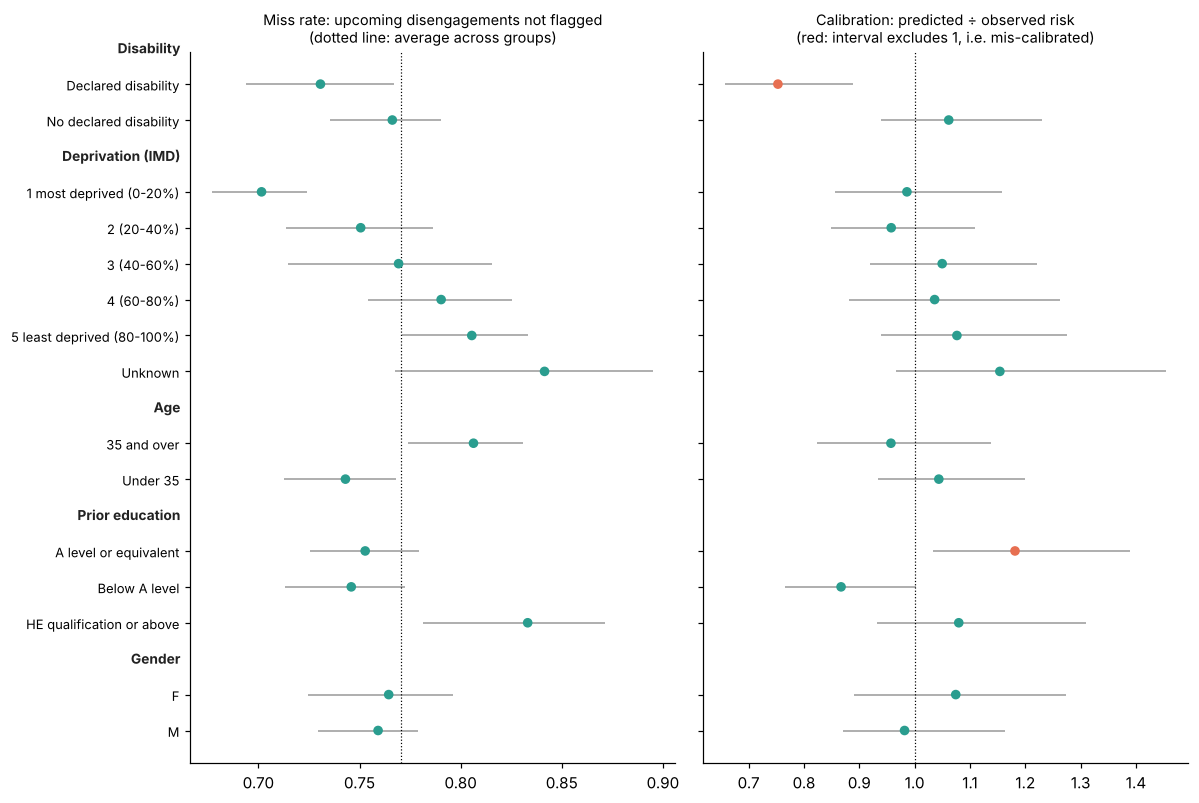

In [2]:
m = gm[gm.score == "Stage 3 model"].copy()
order = ["disability", "imd_quintile", "age_group", "education", "gender"]
titles = {"disability": "Disability", "imd_quintile": "Deprivation (IMD)", "age_group": "Age", "education": "Prior education", "gender": "Gender"}
m["attribute"] = pd.Categorical(m.attribute, order, ordered=True)
m = m.sort_values(["attribute", "group"]).reset_index(drop=True)
# Row positions top-down, with a header row (gap) before each attribute.
pos, headers, cur = [], {}, 0
for a in order:
    headers[a] = cur; cur += 1
    for _ in range((m.attribute == a).sum()):
        pos.append(cur); cur += 1
y = -np.array(pos, dtype=float)
fig, axes = plt.subplots(1, 2, figsize=(11, 7.4), sharey=True)
for ax, col, ref, title in [(axes[0], "miss_rate", None, "Miss rate: upcoming disengagements not flagged\n(dotted line: average across groups)"),
                            (axes[1], "calibration_ratio", 1.0, "Calibration: predicted ÷ observed risk\n(red: interval excludes 1, i.e. mis-calibrated)")]:
    lo, hi = m[f"{col}_lo"], m[f"{col}_hi"]
    colour = np.where((col == "calibration_ratio") & ((hi < 1) | (lo > 1)), "#e76f51", "#2a9d8f")
    ax.errorbar(m[col], y, xerr=[m[col] - lo, hi - m[col]], fmt="none", ecolor="#999", elinewidth=1)
    ax.scatter(m[col], y, c=colour, zorder=3, s=28)
    if ref: ax.axvline(ref, color="black", lw=0.8, ls=":")
    ax.set_title(title, fontsize=9.5)
axes[0].axvline(m.miss_rate.mean(), color="black", lw=0.8, ls=":")
axes[0].set_yticks(y, m.group, fontsize=8.5)
for a in order:
    axes[0].text(-0.02, -headers[a], titles[a], transform=axes[0].get_yaxis_transform(), ha="right",
                 va="center", fontsize=9, fontweight="bold", color="#222")
fig.tight_layout(); fig.savefig(FIG / "stage5_fairness.png", bbox_inches="tight"); plt.show()

Paired gaps against each attribute's reference group (miss rate in percentage points; calibration ratio difference):

In [3]:
g = gaps.copy()
g["miss-rate gap (pp)"] = [f"{x*100:+.1f} [{lo*100:+.1f}, {hi*100:+.1f}]" for x, lo, hi in zip(g.miss_rate_gap, g.miss_gap_lo, g.miss_gap_hi)]
g["calibration gap"] = [f"{x:+.2f} [{lo:+.2f}, {hi:+.2f}]" for x, lo, hi in zip(g.calibration_gap, g.cal_gap_lo, g.cal_gap_hi)]
g[["attribute", "group", "reference", "miss-rate gap (pp)", "calibration gap"]]

,attribute,group,reference,miss-rate gap (pp),calibration gap
0,disability,Declared disability,No declared disability,"-3.6 [-7.7, +0.8]","-0.31 [-0.44, -0.19]"
1,imd_quintile,1 most deprived (0-20%),3 (40-60%),"-6.8 [-10.5, -2.8]","-0.06 [-0.17, +0.02]"
2,imd_quintile,2 (20-40%),3 (40-60%),"-1.9 [-7.0, +3.5]","-0.09 [-0.21, -0.00]"
3,imd_quintile,4 (60-80%),3 (40-60%),"+2.1 [-3.0, +7.0]","-0.01 [-0.11, +0.12]"
4,imd_quintile,5 least deprived (80-100%),3 (40-60%),"+3.6 [-2.0, +9.5]","+0.03 [-0.09, +0.15]"
5,imd_quintile,Unknown,3 (40-60%),"+7.2 [-1.2, +13.7]","+0.10 [-0.08, +0.31]"
6,age_group,35 and over,Under 35,"+6.3 [+3.7, +9.2]","-0.09 [-0.16, -0.00]"
7,gender,F,M,"+0.5 [-2.6, +3.7]","+0.09 [-0.11, +0.27]"
8,education,Below A level,A level or equivalent,"-0.7 [-3.7, +2.1]","-0.31 [-0.42, -0.25]"
9,education,HE qualification or above,A level or equivalent,"+8.0 [+3.1, +12.2]","-0.10 [-0.21, +0.02]"


## 2. Over a whole term: who gets reached in time?

In [4]:
c = cov[cov.score == "Stage 3 model"].pivot_table(index=["attribute", "group"], values=["reached_before_silence", "withdrawers"])
c.round(3)

reached_before_silence  withdrawers
attribute    group                                                          
age_group    35 and over                                  0.472       1448.0
             Under 35                                     0.527       3689.0
disability   Declared disability                          0.573        684.0
             No declared disability                       0.502       4453.0
education    A level or equivalent                        0.525       2056.0
             Below A level                                0.519       2357.0
             HE qualification or above                    0.445        724.0
gender       F                                            0.514       2065.0
             M                                            0.509       3072.0
imd_quintile 1 most deprived (0-20%)                      0.558       1137.0
             2 (20-40%)                                   0.498       1239.0
             3 (40-60%)                                   0.517        983.0
             4 (60-80%)                                   0.494        889.0
             5 least deprived (80-100%)                   0.483        745.0
             Unknown                                      0.465        144.0

## 3. One mitigation: recalibrating by disability

The clearest problem is calibration for students with a declared disability: the model's probabilities understate their risk by about a quarter. A simple fix scales each group's predicted odds so that predicted matches observed. The scaling is estimated on *other* presentations, so the test is honest.

**This uses a protected characteristic at decision time.** Disability is protected under the Equality Act 2010. Using it to direct *more* support may be acceptable, but that is a legal and policy decision for the institution, not a modelling default. It is shown here as an option, with its trade-offs.

In [5]:
before = gm[(gm.score == "Stage 3 model") & (gm.attribute == "disability")].set_index("group")
after = gm[gm.score == "Recalibrated by disability"].set_index("group")
cmp = pd.concat({"before": before[["flag_rate", "miss_rate", "precision", "calibration_ratio"]],
                 "after": after[["flag_rate", "miss_rate", "precision", "calibration_ratio"]]}, axis=1)
tc = cov[cov.attribute == "disability"].pivot(index="group", columns="score", values="reached_before_silence")
display(cmp.round(3)); display(tc.round(3)); overall.round(4)

before                                        \
                       flag_rate miss_rate precision calibration_ratio   
group                                                                    
Declared disability        0.140     0.731     0.099             0.753   
No declared disability     0.096     0.766     0.080             1.062   

                           after                                        
                       flag_rate miss_rate precision calibration_ratio  
group                                                                   
Declared disability        0.265     0.558     0.086             0.979  
No declared disability     0.083     0.790     0.083             1.000

score,Recalibrated by disability,Stage 3 model
group,,
Declared disability,0.738,0.573
No declared disability,0.477,0.502


,score,recall,precision
0,Stage 3 model,0.2387,0.0829
1,Recalibrated by disability,0.2418,0.0839


## 4. Findings

1. **Gender:** no meaningful gaps in miss rate or calibration.
2. **Disability: the model understates risk.** Students with a declared disability are 1.6× as likely to disengage (5.2% vs 3.3% of student-weeks), and the model only partly reflects this: calibration ratio 0.75 vs 1.06 (gap −0.31, interval −0.44 to −0.19). Because their risk is higher, they are still flagged more often and reached slightly more over a term (57% vs 50%). But **the probability a tutor sees understates their risk by about a quarter.**
3. **Prior education: a calibration gap.** Risk is over-predicted for A-level students (ratio 1.18) and somewhat under-predicted below A level (0.87), a significant gap of −0.31. Students with a degree or higher are **missed 8 points more often** (+3.1 to +12.2), and only 45% are reached in time over a term.
4. **Age: students aged 35 and over are missed 6 points more often** (+3.7 to +9.2) than under-35s, and are reached less over a term (47% vs 53%).
5. **Deprivation:** the most deprived quintile is missed *less* (−6.8 points against the middle quintile) and calibration is acceptable across quintiles. Miss rates rise steadily towards less-deprived groups, in line with their lower base rates.
6. **Recalibrating by disability fixes the calibration (0.98) at no cost to overall performance** (recall 23.9% → 24.2%, precision 8.3% → 8.4%). Over a term it raises coverage of disabled withdrawing students from 57% to 74%, while others fall slightly (50% → 48%). It redistributes attention, so the institution should make that choice knowingly.

**What this means for deployment:** report risk alongside group-level calibration; do not show uncalibrated probabilities for groups where the model is known to under-predict; investigate *why* the gaps arise (for example, assistive technology or offline study that VLE logs do not capture) before deciding on group adjustments.

**Limitations:** OULAD's demographics are coarse and self-declared (disability is "declared", not diagnosed); IMD is area-level, not individual; intersections (e.g. older *and* disabled) are not examined because the groups become too small.